<a href="https://colab.research.google.com/github/snehavibes1/unemployment-analysis-python/blob/main/Unemployment_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

# Load the dataset
file_path = '/content/Unemployment in India.csv'
df = pd.read_csv(file_path)

# Display basic information and the first 5 rows
df.info()
display(df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    object 
 1    Date                                     740 non-null    object 
 2    Frequency                                740 non-null    object 
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    object 
dtypes: float64(3), object(4)
memory usage: 42.1+ KB


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


### 1. Data Cleaning and Preprocessing

In [6]:
# Load a fresh copy of the dataset to avoid issues with mutated states
df = pd.read_csv('/content/Unemployment in India.csv')

# Clean column names by stripping whitespace
df.columns = df.columns.str.strip()

# Trim whitespace from categorical string values
for col in ['Region', 'Frequency', 'Area']:
    if col in df.columns:
        df[col] = df[col].astype(str).str.strip()

# Convert 'Date' column safely to datetime
df['Date'] = pd.to_datetime(
    df['Date'].astype(str).str.strip(),
    format='%d-%m-%Y',
    errors='coerce'
)

# Remove completely null rows and duplicates
df = df.dropna(subset=['Date', 'Estimated Unemployment Rate (%)']).drop_duplicates().copy()

print(f"Cleaned dataset shape: {df.shape}")
print(df.isnull().sum())
display(df.head())

Cleaned dataset shape: (740, 7)
Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Area                                       0
dtype: int64


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,2019-05-31,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,2019-06-30,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,2019-07-31,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,2019-08-31,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,2019-09-30,Monthly,5.17,12256762.0,44.68,Rural


### 2. High-Level Metrics & Segment Analysis

In [4]:
unemployment_col = 'Estimated Unemployment Rate (%)'

# Overall Average Unemployment
avg_unemployment = df[unemployment_col].mean()
print(f"Average Unemployment Rate: {avg_unemployment:.2f}%\n")

# Average Unemployment by Area (Rural vs Urban)
print("Average Unemployment by Area:")
area_metrics = df.groupby('Area')[unemployment_col].mean().round(2).reset_index()
display(area_metrics)

# Top 10 Regions with Highest Average Unemployment Rates
print("\nTop 10 Regions with Highest Average Unemployment:")
region_metrics = df.groupby('Region')[unemployment_col].mean().sort_values(ascending=False).round(2).head(10).reset_index()
display(region_metrics)

Average Unemployment Rate: nan%

Average Unemployment by Area:


,Area,Estimated Unemployment Rate (%)



Top 10 Regions with Highest Average Unemployment:


,Region,Estimated Unemployment Rate (%)


### 3. Data Visualizations

First 5 rows:


,Region,Date,Frequency,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%),Area
0,Andhra Pradesh,31-05-2019,Monthly,3.65,11999139.0,43.24,Rural
1,Andhra Pradesh,30-06-2019,Monthly,3.05,11755881.0,42.05,Rural
2,Andhra Pradesh,31-07-2019,Monthly,3.75,12086707.0,43.50,Rural
3,Andhra Pradesh,31-08-2019,Monthly,3.32,12285693.0,43.97,Rural
4,Andhra Pradesh,30-09-2019,Monthly,5.17,12256762.0,44.68,Rural


Dataset shape: (768, 7)

Column names:
['Region', ' Date', ' Frequency', ' Estimated Unemployment Rate (%)', ' Estimated Employed', ' Estimated Labour Participation Rate (%)', 'Area']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 7 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   Region                                    740 non-null    object 
 1    Date                                     740 non-null    object 
 2    Frequency                                740 non-null    object 
 3    Estimated Unemployment Rate (%)          740 non-null    float64
 4    Estimated Employed                       740 non-null    float64
 5    Estimated Labour Participation Rate (%)  740 non-null    float64
 6   Area                                      740 non-null    object 
dtypes: float64(3), object(4)
memory usage: 42.1+ K

,Estimated Unemployment Rate (%),Estimated Employed,Estimated Labour Participation Rate (%)
count,740.000000,7.400000e+02,740.000000
mean,11.787946,7.204460e+06,42.630122
std,10.721298,8.087988e+06,8.111094
min,0.000000,4.942000e+04,13.330000
25%,4.657500,1.190404e+06,38.062500
50%,8.350000,4.744178e+06,41.160000
75%,15.887500,1.127549e+07,45.505000
max,76.740000,4.577751e+07,72.570000


Missing values before cleaning:
Region                                      0
Date                                       28
Frequency                                   0
Estimated Unemployment Rate (%)            28
Estimated Employed                         28
Estimated Labour Participation Rate (%)    28
Area                                        0
dtype: int64

Shape after cleaning: (740, 7)

Missing values after cleaning:
Region                                     0
Date                                       0
Frequency                                  0
Estimated Unemployment Rate (%)            0
Estimated Employed                         0
Estimated Labour Participation Rate (%)    0
Area                                       0
dtype: int64


...

,Estimated Unemployment Rate (%)
Area,
Rural,10.32
Urban,13.17



Average unemployment by region:


,Estimated Unemployment Rate (%)
Region,
Tripura,28.35
Haryana,26.28
Jharkhand,20.58
Bihar,18.92
Himachal Pradesh,18.54
Delhi,16.50
Jammu & Kashmir,16.19
Chandigarh,15.99
Rajasthan,14.06



Highest unemployment observations:


,Region,Date,Area,Estimated Unemployment Rate (%)
627,Puducherry,2020-04-30,Urban,76.74
628,Puducherry,2020-05-31,Urban,75.00
242,Puducherry,2020-04-30,Rural,74.51
531,Jharkhand,2020-05-31,Urban,70.17
530,Jharkhand,2020-04-30,Urban,61.48
412,Bihar,2020-04-30,Urban,58.77
145,Jharkhand,2020-05-31,Rural,55.10
287,Tamil Nadu,2020-04-30,Rural,53.19
507,Himachal Pradesh,2020-05-31,Urban,50.00
38,Bihar,2020-05-31,Rural,47.26


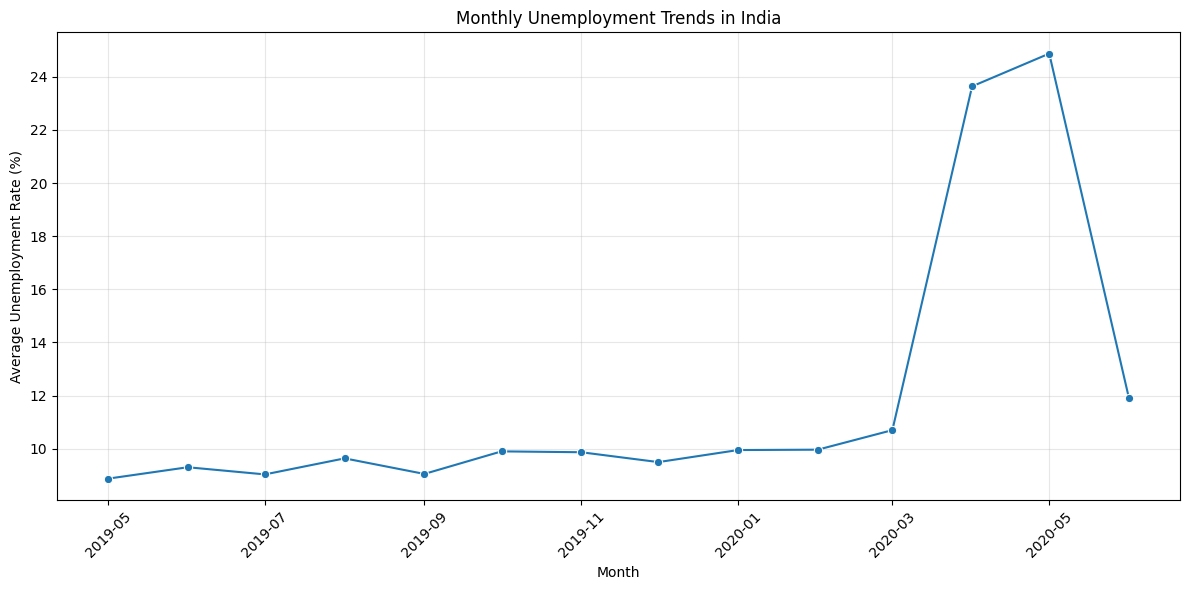

,mean,median,count
COVID Period,,,
COVID Onset,17.77,14.52,204
Pre-COVID,9.51,7.12,536


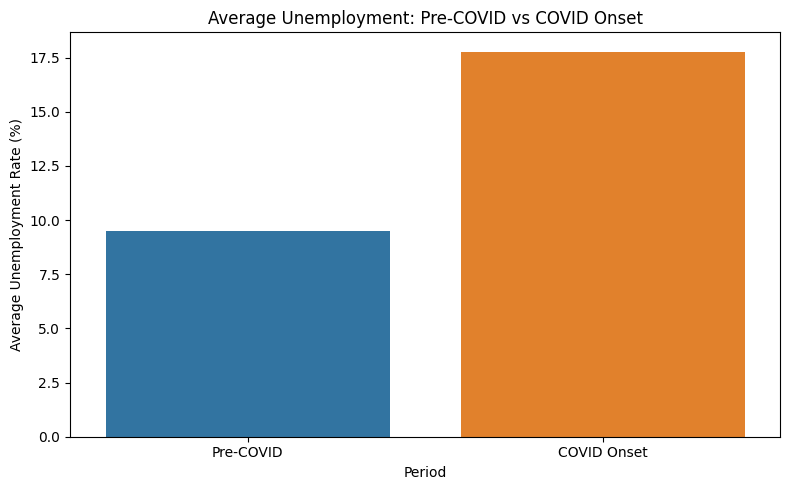

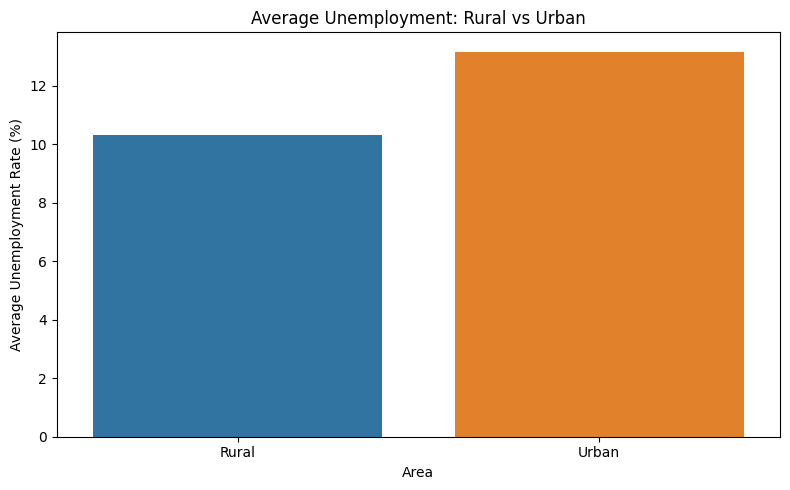

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Reload the dataset from fresh file to avoid empty DataFrame issues
df = pd.read_csv('/content/Unemployment in India.csv')

print("First 5 rows:")
display(df.head())

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(df.describe())

# Remove extra spaces from column names
df.columns = df.columns.str.strip()

# Remove extra spaces from text columns
for col in ["Region", "Frequency", "Area"]:
    if col in df.columns:
        df[col] = df[col].astype(str).str.strip()

# Convert dates to datetime format
df["Date"] = pd.to_datetime(
    df["Date"].astype(str).str.strip(),
    format="%d-%m-%Y",
    errors="coerce"
)

# Check missing values
print("Missing values before cleaning:")
print(df.isnull().sum())

# Remove duplicate rows
df = df.drop_duplicates()

# Remove rows missing essential analysis fields
df = df.dropna(
    subset=["Date", "Estimated Unemployment Rate (%)"]
).copy()

# Check the cleaned dataset
print("\nShape after cleaning:", df.shape)
print("\nMissing values after cleaning:")
print(df.isnull().sum())

display(df.head())

unemployment_col = "Estimated Unemployment Rate (%)"

print("Average unemployment rate:",
      round(df[unemployment_col].mean(), 2), "%")

print("\nAverage unemployment by area:")
display(
    df.groupby("Area")[unemployment_col]
      .mean()
      .round(2)
)

print("\nAverage unemployment by region:")
display(
    df.groupby("Region")[unemployment_col]
      .mean()
      .sort_values(ascending=False)
      .round(2)
)

print("\nHighest unemployment observations:")
display(
    df.nlargest(10, unemployment_col)[
        ["Region", "Date", "Area", unemployment_col]
    ]
)

# Calculate monthly average unemployment
df["YearMonth"] = df["Date"].dt.to_period("M").dt.to_timestamp()

monthly_unemployment = (
    df.groupby("YearMonth")[unemployment_col]
      .mean()
      .reset_index()
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_unemployment,
    x="YearMonth",
    y=unemployment_col,
    marker="o"
)

plt.title("Monthly Unemployment Trends in India")
plt.xlabel("Month")
plt.ylabel("Average Unemployment Rate (%)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

df["COVID Period"] = np.where(
    df["Date"] < pd.Timestamp("2020-03-01"),
    "Pre-COVID",
    "COVID Onset"
)

covid_comparison = (
    df.groupby("COVID Period")[unemployment_col]
      .agg(["mean", "median", "count"])
      .round(2)
)

display(covid_comparison)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="COVID Period",
    y=unemployment_col,
    hue="COVID Period",
    legend=False,
    errorbar=None
)

plt.title("Average Unemployment: Pre-COVID vs COVID Onset")
plt.xlabel("Period")
plt.ylabel("Average Unemployment Rate (%)")
plt.tight_layout()
plt.show()

area_unemployment = (
    df.groupby("Area")[unemployment_col]
      .mean()
      .reset_index()
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=area_unemployment,
    x="Area",
    y=unemployment_col,
    hue="Area",
    legend=False,
    errorbar=None
)

plt.title("Average Unemployment: Rural vs Urban")
plt.xlabel("Area")
plt.ylabel("Average Unemployment Rate (%)")
plt.tight_layout()
plt.show()

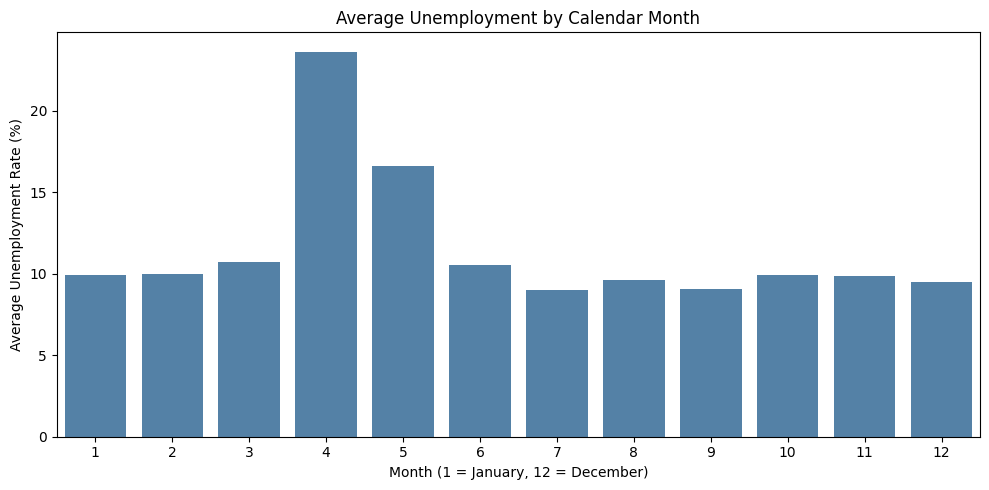

In [9]:

df["Month"] = df["Date"].dt.month

monthly_pattern = (
    df.groupby("Month")[unemployment_col]
      .mean()
      .reset_index()
)

plt.figure(figsize=(10, 5))

sns.barplot(
    data=monthly_pattern,
    x="Month",
    y=unemployment_col,
    color="steelblue",
    errorbar=None
)

plt.title("Average Unemployment by Calendar Month")
plt.xlabel("Month (1 = January, 12 = December)")
plt.ylabel("Average Unemployment Rate (%)")
plt.tight_layout()
plt.show()

In [10]:

df.to_csv("cleaned_unemployment_data.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [11]:

from google.colab import files

files.download("cleaned_unemployment_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>